<a href="https://colab.research.google.com/github/owel569/Atelier2-CASANDRA/blob/main/03_GPU_PyTorch_ONNX_TensorRT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 – Pipeline GPU n°1 : PyTorch → ONNX → TensorRT → CUDA/cuDNN → GPU

| Couche | Technologie |
|---|---|
| Haut niveau | PyTorch (ResNet-18 pré-entraîné ImageNet) |
| Format du modèle | ONNX |
| Middle level | TensorRT (fusion d'opérateurs, choix des kernels, option FP16) |
| Bas niveau | CUDA et cuDNN |
| Matériel | GPU Google Colab (NVIDIA) |

Le moteur TensorRT est construit en **FP32** (pipeline principal, comparable aux autres) et en **FP16** (variante : gain de débit vs. précision).

**Runtime Colab obligatoire : GPU (Modifier > Paramètres du notebook > GPU T4).**

In [22]:
!pip -q install onnxconverter-common

In [12]:
!nvidia-smi
!pip -q install onnx tensorrt nvidia-ml-py

Tue Nov 24 14:56:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [13]:
import os, sys, time, json, hashlib, platform, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torchvision
from torchvision import transforms, datasets, models
from torchvision.transforms import InterpolationMode

# ====== PARAMÈTRES EXPÉRIMENTAUX (NE PAS MODIFIER : identiques dans les 4 notebooks) ======
SEED       = 42     # graine : même sous-ensemble de 50 images partout
N_IMAGES   = 50     # nombre d'images CIFAR-10 (jeu de test)
BATCH_SIZE = 10     # taille de batch (50 = 5 batchs)
IMG_SIZE   = 224    # taille d'entrée de ResNet-18
N_WARMUP   = 5      # passes de chauffe (exclues des mesures)
N_RUNS     = 5      # exécutions indépendantes (>= 3 exigé par l'énoncé)
N_PASSES   = 10     # nombre de passes sur les 50 images par exécution (mesures plus stables, énergie mesurable)
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130


In [14]:
assert torch.cuda.is_available(), "Active un runtime GPU dans Colab !"

In [15]:
# ---------- Données : 50 images du jeu de test CIFAR-10 ----------
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck"]

# ResNet-18 a été pré-entraîné sur ImageNet (1000 classes), pas sur CIFAR-10.
# Pour calculer une précision Top-1 sur 10 classes, on associe chaque classe CIFAR-10
# à un groupe de classes ImageNet. Score d'une classe CIFAR = max des logits de son groupe.
IMAGENET_GROUPS = {
    "airplane":   [404, 895, 908],
    "automobile": [436, 468, 511, 609, 627, 656, 661, 751, 817],
    "bird":       list(range(7, 25)) + list(range(80, 101)) + list(range(127, 147)),
    "cat":        [281, 282, 283, 284, 285],
    "deer":       [351, 352, 353],
    "dog":        list(range(151, 269)),
    "frog":       [30, 31, 32],
    "horse":      [339, 603],
    "ship":       [403, 472, 484, 510, 554, 625, 628, 724, 780, 814, 833, 871, 914],
    "truck":      [555, 569, 675, 717, 734, 864, 867],
}
GROUPS = [np.array(IMAGENET_GROUPS[c]) for c in CIFAR_CLASSES]

def to_cifar(logits):
    """logits ImageNet (N,1000) -> classe CIFAR-10 prédite (N,)"""
    scores = np.stack([logits[:, g].max(axis=1) for g in GROUPS], axis=1)
    return scores.argmax(axis=1)

# Prétraitement identique à celui du pré-entraînement ImageNet : redimensionnement + normalisation
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

ds = datasets.CIFAR10(root="data", train=False, download=True)
idx = np.random.RandomState(SEED).choice(len(ds), N_IMAGES, replace=False).astype(np.int64)
labels = np.array([ds[int(i)][1] for i in idx])
X = torch.stack([tfm(ds[int(i)][0]) for i in idx]).contiguous()     # (50, 3, 224, 224) float32
SUBSET_HASH = hashlib.md5(idx.tobytes()).hexdigest()
print("X :", tuple(X.shape), X.dtype, "| hash du sous-ensemble :", SUBSET_HASH)
print("Répartition des classes :", dict(zip(CIFAR_CLASSES, np.bincount(labels, minlength=10).tolist())))

# Vérification visuelle des groupes (noms ImageNet réellement associés)
IN_NAMES = models.ResNet18_Weights.IMAGENET1K_V1.meta["categories"]
for c, g in zip(CIFAR_CLASSES, GROUPS):
    print(f"{c:11s} <- {len(g):3d} classes ImageNet, ex. : {[IN_NAMES[i] for i in g[:4]]}")

X : (50, 3, 224, 224) torch.float32 | hash du sous-ensemble : 3fb089145f7501be08d1825dfa25324f
Répartition des classes : {'airplane': 4, 'automobile': 4, 'bird': 7, 'cat': 5, 'deer': 3, 'dog': 9, 'frog': 5, 'horse': 4, 'ship': 5, 'truck': 4}
airplane    <-   3 classes ImageNet, ex. : ['airliner', 'warplane', 'wing']
automobile  <-   9 classes ImageNet, ex. : ['beach wagon', 'cab', 'convertible', 'jeep']
bird        <-  59 classes ImageNet, ex. : ['cock', 'hen', 'ostrich', 'brambling']
cat         <-   5 classes ImageNet, ex. : ['tabby', 'tiger cat', 'Persian cat', 'Siamese cat']
deer        <-   3 classes ImageNet, ex. : ['hartebeest', 'impala', 'gazelle']
dog         <- 118 classes ImageNet, ex. : ['Chihuahua', 'Japanese spaniel', 'Maltese dog', 'Pekinese']
frog        <-   3 classes ImageNet, ex. : ['bullfrog', 'tree frog', 'tailed frog']
horse       <-   2 classes ImageNet, ex. : ['sorrel', 'horse cart']
ship        <-  13 classes ImageNet, ex. : ['aircraft carrier', 'canoe', 'catam

In [16]:
# ---------- Modèle PyTorch pré-entraîné + référence (eager, CPU, FP32) ----------
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1

def load_model():
    return models.resnet18(weights=WEIGHTS).eval()

ref_model = load_model()
with torch.inference_mode():
    ref_logits = torch.cat([ref_model(b) for b in X.split(BATCH_SIZE)]).numpy()
ref_pred = to_cifar(ref_logits)
print("Top-1 de référence (PyTorch eager CPU FP32) :", (ref_pred == labels).mean())

Top-1 de référence (PyTorch eager CPU FP32) : 0.66


In [17]:
# ---------- Informations sur l'environnement (à citer dans le rapport) ----------
def _cpu_name():
    try:
        for l in open("/proc/cpuinfo"):
            if l.startswith("model name"):
                return l.split(":")[1].strip()
    except Exception:
        pass
    return platform.processor()

ENV = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cpu": _cpu_name(),
    "cpu_count": os.cpu_count(),
    "torch_threads": torch.get_num_threads(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
}
print(json.dumps(ENV, indent=2))

{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "cpu": "Intel(R) Xeon(R) CPU @ 2.00GHz",
  "cpu_count": 2,
  "torch_threads": 1,
  "gpu": "Tesla T4",
  "cuda": "13.0",
  "cudnn": 92800
}


In [18]:
# ---------- Mesure d'énergie (best effort) ----------
class EnergyMeter:
    """GPU : compteur d'énergie NVML (mJ).  CPU : compteur Intel RAPL si lisible.
    Si indisponible -> None (l'énoncé autorise 'lorsque les mesures sont disponibles')."""
    def __init__(self, kind):
        self.kind, self.ok = kind, False
        if kind == "gpu":
            try:
                import pynvml
                pynvml.nvmlInit()
                self.nv = pynvml
                self.h = pynvml.nvmlDeviceGetHandleByIndex(0)
                pynvml.nvmlDeviceGetTotalEnergyConsumption(self.h)
                self.ok = True
            except Exception as e:
                print("[énergie GPU indisponible]", e)
        else:
            self.p = "/sys/class/powercap/intel-rapl:0/"
            try:
                open(self.p + "energy_uj").read()
                self.max_j = int(open(self.p + "max_energy_range_uj").read()) / 1e6
                self.ok = True
            except Exception as e:
                print("[énergie CPU (RAPL) indisponible]", e)

    def read(self):
        if not self.ok: return None
        if self.kind == "gpu":
            return self.nv.nvmlDeviceGetTotalEnergyConsumption(self.h) / 1000.0
        return int(open(self.p + "energy_uj").read()) / 1e6

    def delta(self, a, b):
        if a is None or b is None: return None
        d = b - a
        if self.kind == "cpu" and d < 0: d += self.max_j
        return d


METRICS = ["throughput", "pass_s", "batch_ms", "img_ms", "energy_j", "energy_per_img_j", "power_w"]

def _stats(runs, key):
    v = [r[key] for r in runs if r.get(key) is not None]
    if len(v) == 0: return None
    v = np.array(v, dtype=float)
    return {"mean": float(v.mean()), "std": float(v.std(ddof=1)) if len(v) > 1 else 0.0,
            "min": float(v.min()), "max": float(v.max())}


def benchmark(pid, label, group, hw, infer_fn, build_time_s=None, is_main=True, extra=None):
    """infer_fn(batch_cpu_tensor) -> logits numpy (B,1000) sur CPU.
    La mesure inclut donc les transferts hôte<->device (même définition pour les 4 pipelines)."""
    batches = list(X.split(BATCH_SIZE))
    print(f"\n=== {label} ===")
    for _ in range(N_WARMUP):                       # chauffe (hors mesure)
        for b in batches: infer_fn(b)
    meter, runs, last_logits = EnergyMeter(hw), [], None
    n = N_IMAGES * N_PASSES
    for r in range(N_RUNS):
        lat, e0, t0 = [], meter.read(), time.perf_counter()
        for _ in range(N_PASSES):
            outs = []
            for b in batches:
                tb = time.perf_counter()
                outs.append(infer_fn(b))
                lat.append(time.perf_counter() - tb)
        t = time.perf_counter() - t0
        E = meter.delta(e0, meter.read())
        logits = np.concatenate(outs)
        if last_logits is not None:
            assert np.abs(logits - last_logits).max() < 1e-2, "sorties instables entre exécutions"
        last_logits = logits
        runs.append({
            "throughput": n / t,                   # images / s
            "pass_s": t / N_PASSES,                # temps pour traiter les 50 images (s)
            "batch_ms": 1000 * float(np.mean(lat)),# latence moyenne par batch (ms)
            "img_ms": 1000 * t / n,                # latence moyenne par image (ms)
            "energy_j": E,
            "energy_per_img_j": None if E is None else E / n,
            "power_w": None if E is None else E / t,
        })
        print(f"  run {r+1}/{N_RUNS} : {runs[-1]['throughput']:8.1f} img/s | {runs[-1]['pass_s']*1000:7.1f} ms / 50 img")
    pred = to_cifar(last_logits)
    result = {
        "id": pid, "label": label, "group": group, "hw": hw, "is_main": is_main,
        "build_time_s": build_time_s, "env": ENV, "extra": extra or {},
        "config": dict(SEED=SEED, N_IMAGES=N_IMAGES, BATCH_SIZE=BATCH_SIZE, N_WARMUP=N_WARMUP,
                       N_RUNS=N_RUNS, N_PASSES=N_PASSES, SUBSET_HASH=SUBSET_HASH),
        "runs": runs,
        "stats": {k: _stats(runs, k) for k in METRICS},
        "accuracy": {
            "top1": float((pred == labels).mean()),
            "agreement_with_ref": float((pred == ref_pred).mean()),
            "imagenet_argmax_agreement": float((last_logits.argmax(1) == ref_logits.argmax(1)).mean()),
            "max_abs_logit_diff_vs_ref": float(np.abs(last_logits - ref_logits).max()),
        },
        "predictions": pred.tolist(), "labels": labels.tolist(),
    }
    with open(f"{RESULTS_DIR}/{pid}.json", "w") as f:
        json.dump(result, f, indent=1)
    s = result["stats"]
    print(f"  -> débit {s['throughput']['mean']:.1f} ± {s['throughput']['std']:.1f} img/s | "
          f"Top-1 {result['accuracy']['top1']:.2%} | accord avec réf. {result['accuracy']['agreement_with_ref']:.2%}")
    return result


def summary_table(results):
    rows = []
    for r in results:
        row = {"pipeline": r["label"], "build (s)": r["build_time_s"]}
        for k, name in [("throughput", "img/s"), ("pass_s", "s/50img"), ("batch_ms", "ms/batch"), ("energy_per_img_j", "J/img")]:
            s = r["stats"][k]
            row[name + " moy"] = None if s is None else s["mean"]
            row[name + " std"] = None if s is None else s["std"]
            row[name + " min"] = None if s is None else s["min"]
            row[name + " max"] = None if s is None else s["max"]
        row["Top-1"] = r["accuracy"]["top1"]
        row["accord réf."] = r["accuracy"]["agreement_with_ref"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("pipeline").T


def plot_own(results, fname):
    """Graphiques propres à ce notebook (la comparaison des 4 pipelines est dans le notebook 05)."""
    labs = [r["label"] for r in results]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    m = [r["stats"]["throughput"]["mean"] for r in results]
    s = [r["stats"]["throughput"]["std"] for r in results]
    ax[0].bar(labs, m, yerr=s, capsize=5, color="tab:blue"); ax[0].set_ylabel("images / s"); ax[0].set_title("Débit (moyenne ± écart-type)")
    m = [r["stats"]["pass_s"]["mean"] * 1000 for r in results]
    s = [r["stats"]["pass_s"]["std"] * 1000 for r in results]
    ax[1].bar(labs, m, yerr=s, capsize=5, color="tab:orange"); ax[1].set_ylabel("ms pour 50 images"); ax[1].set_title("Temps d'inférence (50 images)")
    for r in results:
        ax[2].plot(range(1, N_RUNS + 1), [x["throughput"] for x in r["runs"]], "o-", label=r["label"])
    ax[2].set_xlabel("exécution"); ax[2].set_ylabel("images / s"); ax[2].set_title("Variabilité run par run"); ax[2].legend(fontsize=7)
    for a in ax[:2]: a.tick_params(axis="x", rotation=15)
    plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig(f"figures/{fname}", dpi=150); plt.show()


def download_results():
    try:
        from google.colab import files
        import shutil
        shutil.make_archive("results_export", "zip", RESULTS_DIR)
        files.download("results_export.zip")
    except Exception as e:
        print("Hors Colab / téléchargement impossible :", e, "-> récupère le dossier results/ à la main.")

## 1. Export PyTorch → ONNX

In [19]:
# ---------- Export PyTorch -> ONNX (batch fixe = BATCH_SIZE) ----------
import onnx
ONNX_PATH = "resnet18.onnx"
m_export = load_model()
t0 = time.perf_counter()
try:
    torch.onnx.export(m_export, X[:BATCH_SIZE], ONNX_PATH, input_names=["input"], output_names=["logits"],
                      opset_version=17, dynamo=False)
except TypeError:   # anciennes versions de torch : pas d'argument dynamo
    torch.onnx.export(m_export, X[:BATCH_SIZE], ONNX_PATH, input_names=["input"], output_names=["logits"],
                      opset_version=17)
onnx_export_s = time.perf_counter() - t0
onnx.checker.check_model(onnx.load(ONNX_PATH))
print(f"ONNX exporté en {onnx_export_s:.2f}s | taille : {os.path.getsize(ONNX_PATH)/1e6:.1f} Mo")

/tmp/ipykernel_379/3150183871.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m_export, X[:BATCH_SIZE], ONNX_PATH, input_names=["input"], output_names=["logits"],


ONNX exporté en 1.55s | taille : 46.7 Mo


## 2. Construction du moteur TensorRT
`build_serialized_network` : TensorRT analyse le graphe, fusionne les couches (Conv+BN+ReLU…), teste plusieurs kernels CUDA/cuDNN
pour chaque couche (*autotuning*) et produit un *engine* optimisé pour **ce** GPU. Le temps de build est mesuré à part.

In [20]:
import tensorrt as trt
print("TensorRT", trt.__version__)
ENV["tensorrt"] = trt.__version__
TRT_LOGGER = trt.Logger(trt.Logger.WARNING)

def build_engine(onnx_path, fp16=False):
    builder = trt.Builder(TRT_LOGGER)
    flag = 0
    if hasattr(trt.NetworkDefinitionCreationFlag, "EXPLICIT_BATCH"):      # TensorRT < 10
        flag = 1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
    network = builder.create_network(flag)
    parser = trt.OnnxParser(network, TRT_LOGGER)
    with open(onnx_path, "rb") as f:
        if not parser.parse(f.read()):
            for i in range(parser.num_errors): print(parser.get_error(i))
            raise RuntimeError("Échec du parsing ONNX")
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
    if fp16:
        config.set_flag(trt.BuilderFlag.FP16)
    t0 = time.perf_counter()
    blob = builder.build_serialized_network(network, config)
    build_s = time.perf_counter() - t0
    engine = trt.Runtime(TRT_LOGGER).deserialize_cuda_engine(blob)
    return engine, build_s


class TRTRunner:
    """Exécute l'engine ; entrée = tenseur CPU, sortie = numpy CPU (même définition que les autres pipelines)."""
    def __init__(self, engine):
        self.engine = engine
        self.ctx = engine.create_execution_context()
        names = [engine.get_tensor_name(i) for i in range(engine.num_io_tensors)]
        self.in_name = [n for n in names if engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT][0]
        self.out_name = [n for n in names if engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT][0]
        self.d_in = torch.empty((BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE), dtype=torch.float32, device="cuda")
        self.d_out = torch.empty((BATCH_SIZE, 1000), dtype=torch.float32, device="cuda")
        self.ctx.set_tensor_address(self.in_name, self.d_in.data_ptr())
        self.ctx.set_tensor_address(self.out_name, self.d_out.data_ptr())
    def __call__(self, x):
        self.d_in.copy_(x)
        self.ctx.execute_async_v3(torch.cuda.current_stream().cuda_stream)
        return self.d_out.cpu().numpy()          # .cpu() synchronise le flux

TensorRT 11.5.0.63


## 3. Mesures : TensorRT FP32 (pipeline principal) puis FP16 (variante)

In [21]:
results = []
for prec in ["fp32", "fp16"]:
    engine, build_s = build_engine(ONNX_PATH, fp16=(prec == "fp16"))
    print(f"[{prec}] engine construit en {build_s:.1f}s | taille sérialisée ≈ {engine.serialize().nbytes/1e6:.1f} Mo")
    runner = TRTRunner(engine)
    res = benchmark(
        pid=f"gpu1_pytorch_onnx_tensorrt_{prec}",
        label=f"GPU 1 : PyTorch→ONNX→TensorRT ({prec.upper()})",
        group="gpu1", hw="gpu", infer_fn=runner,
        build_time_s=onnx_export_s + build_s, is_main=(prec == "fp32"),
        extra={"precision": prec, "trt_build_s": build_s, "onnx_export_s": onnx_export_s},
    )
    results.append(res)
    del runner, engine
summary_table(results)

[fp32] engine construit en 7.5s | taille sérialisée ≈ 54.2 Mo

=== GPU 1 : PyTorch→ONNX→TensorRT (FP32) ===
  run 1/5 :   1171.4 img/s |    42.7 ms / 50 img
  run 2/5 :   1164.7 img/s |    42.9 ms / 50 img
  run 3/5 :   1161.1 img/s |    43.1 ms / 50 img
  run 4/5 :   1162.9 img/s |    43.0 ms / 50 img
  run 5/5 :   1158.2 img/s |    43.2 ms / 50 img
  -> débit 1163.7 ± 5.0 img/s | Top-1 66.00% | accord avec réf. 100.00%


AttributeError: type object 'tensorrt_bindings.tensorrt.BuilderFlag' has no attribute 'FP16'

In [23]:
from onnxconverter_common import float16
ONNX_FP16_PATH = "resnet18_fp16.onnx"
onnx.save(float16.convert_float_to_float16(onnx.load(ONNX_PATH), keep_io_types=True), ONNX_FP16_PATH)

def build_engine(onnx_path, fp16=False):
    builder = trt.Builder(TRT_LOGGER)
    flag = 0
    if hasattr(trt.NetworkDefinitionCreationFlag, "EXPLICIT_BATCH"):      # TensorRT < 10
        flag |= 1 << int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH)
    legacy_fp16 = fp16 and hasattr(trt.BuilderFlag, "FP16")               # anciennes versions
    if fp16 and not legacy_fp16:                                          # versions récentes : réseau fortement typé
        flag |= 1 << int(trt.NetworkDefinitionCreationFlag.STRONGLY_TYPED)
    network = builder.create_network(flag)
    parser = trt.OnnxParser(network, TRT_LOGGER)
    path = ONNX_FP16_PATH if (fp16 and not legacy_fp16) else onnx_path
    with open(path, "rb") as f:
        if not parser.parse(f.read()):
            for i in range(parser.num_errors): print(parser.get_error(i))
            raise RuntimeError("Échec du parsing ONNX")
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
    if legacy_fp16:
        config.set_flag(trt.BuilderFlag.FP16)
    t0 = time.perf_counter()
    blob = builder.build_serialized_network(network, config)
    build_s = time.perf_counter() - t0
    return trt.Runtime(TRT_LOGGER).deserialize_cuda_engine(blob), build_s

/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 2.3695349682384403e-08 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -4.769529660109129e-09 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 8.528004475317141e-17 will be truncated to 1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.037211034503102e-16 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:70: UserWarning: the float32 number -1.6570577798802333e-08 will be truncated to -1e-07
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxconverter_common/float16.py:52: UserWarning: the float32 number 1.011691381710

In [24]:
engine, build_s = build_engine(ONNX_PATH, fp16=True)
print(f"[fp16] engine construit en {build_s:.1f}s")
runner = TRTRunner(engine)
res16 = benchmark(
    pid="gpu1_pytorch_onnx_tensorrt_fp16",
    label="GPU 1 : PyTorch→ONNX→TensorRT (FP16)",
    group="gpu1", hw="gpu", infer_fn=runner,
    build_time_s=onnx_export_s + build_s, is_main=False,
    extra={"precision": "fp16", "trt_build_s": build_s, "onnx_export_s": onnx_export_s},
)
summary_table(results + [res16])

[fp16] engine construit en 23.9s

=== GPU 1 : PyTorch→ONNX→TensorRT (FP16) ===
  run 1/5 :   2979.8 img/s |    16.8 ms / 50 img
  run 2/5 :   2934.0 img/s |    17.0 ms / 50 img
  run 3/5 :   2965.5 img/s |    16.9 ms / 50 img
  run 4/5 :   2996.6 img/s |    16.7 ms / 50 img
  run 5/5 :   2942.2 img/s |    17.0 ms / 50 img
  -> débit 2963.6 ± 25.9 img/s | Top-1 66.00% | accord avec réf. 100.00%


pipeline,GPU 1 : PyTorch→ONNX→TensorRT (FP32),GPU 1 : PyTorch→ONNX→TensorRT (FP16)
build (s),9.053309,25.453559
img/s moy,1163.662484,2963.641913
img/s std,4.971089,25.907663
img/s min,1158.160906,2934.047546
img/s max,1171.441181,2996.609319
s/50img moy,0.042968,0.016872
s/50img std,0.000183,0.000147
s/50img min,0.042682,0.016686
s/50img max,0.043172,0.017041
ms/batch moy,8.591125,3.372296


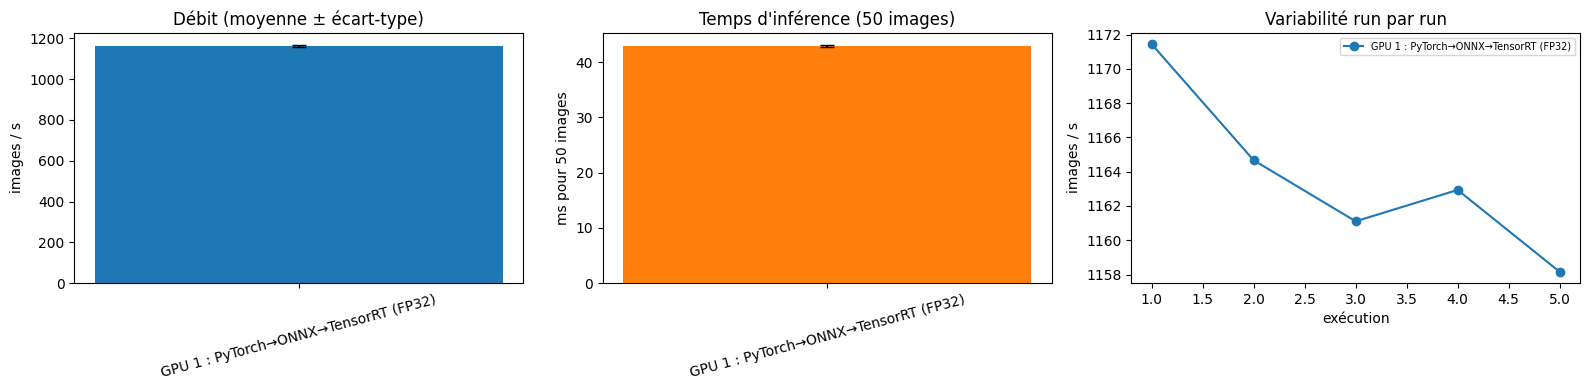

In [25]:
plot_own(results, "gpu1_tensorrt.png")

## 4. Analyse (à rédiger pour le rapport)
- Gain FP16 vs FP32 ? Perte de précision (Top-1, accord avec la référence, écart max sur les logits) ?
- Le coût du build TensorRT est-il amorti ? À partir de combien d'images ?
- Stabilité des mesures sur GPU (horloges, température, autres utilisateurs de la machine Colab) ?
- Énergie par image : quelle est la différence entre FP32 et FP16 ?

In [26]:
download_results()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>